Day 10: Mantle Convection Time Evolution
Rayleigh number = 2500.0

Starting simulation...
Step 100, time=0.002004, max speed=605.13, Nu_bottom=1.46505
Step 200, time=0.002536, max speed=1013.6, Nu_bottom=6.02002
Step 300, time=0.002937, max speed=1144.7, Nu_bottom=13.26038
Step 400, time=0.003322, max speed=1088.8, Nu_bottom=16.82776
Step 500, time=0.003737, max speed=1029.4, Nu_bottom=17.63225
Step 600, time=0.004174, max speed=970.93, Nu_bottom=17.22427
Step 700, time=0.004638, max speed=913.46, Nu_bottom=16.25571
Step 800, time=0.005132, max speed=859.91, Nu_bottom=15.11156
Step 900, time=0.005656, max speed=810.16, Nu_bottom=13.97869
Step 1000, time=0.006213, max speed=761.3, Nu_bottom=13.47622
Step 1100, time=0.006809, max speed=706.72, Nu_bottom=13.61312
Step 1200, time=0.007447, max speed=667.92, Nu_bottom=13.03811
Step 1300, time=0.008127, max speed=611.73, Nu_bottom=12.13205
Step 1400, time=0.008882, max speed=553.08, Nu_bottom=10.80411
Step 1500, time=0.009698, max speed=524.

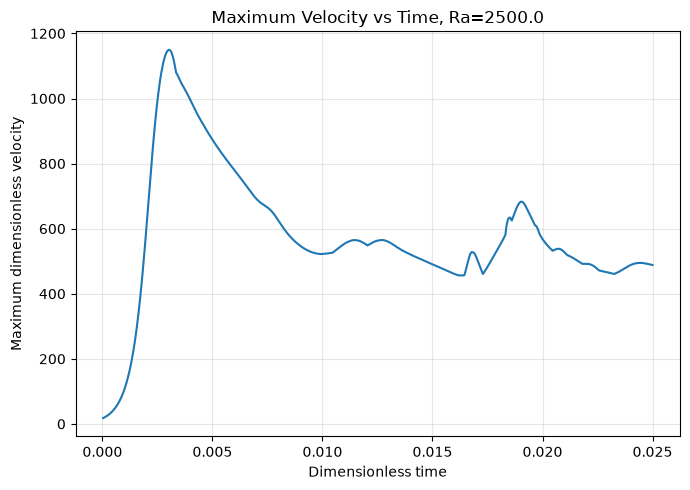

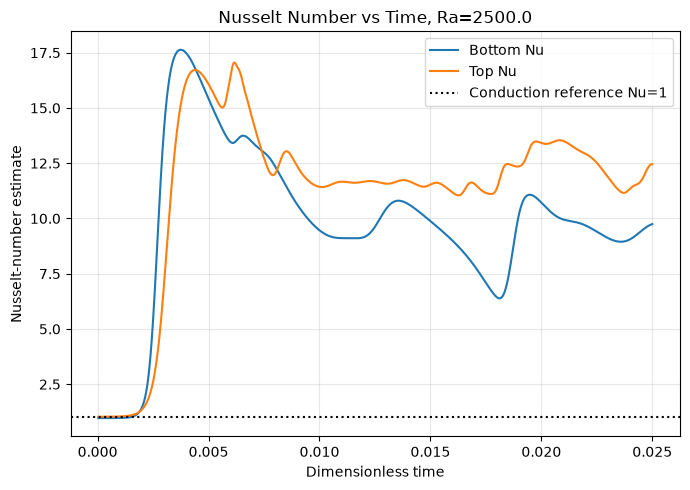

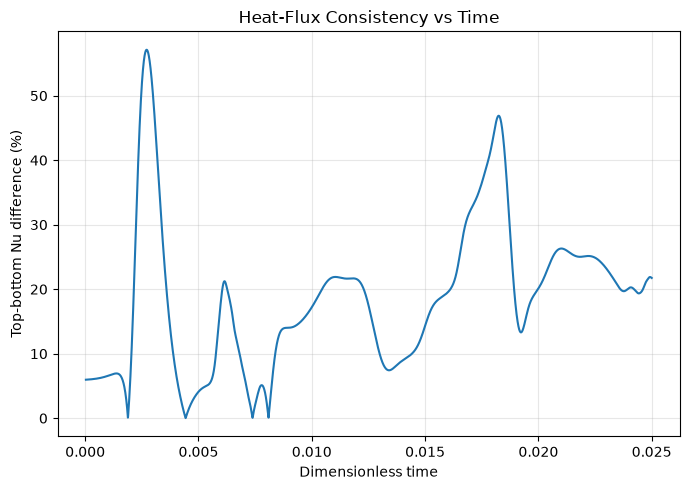

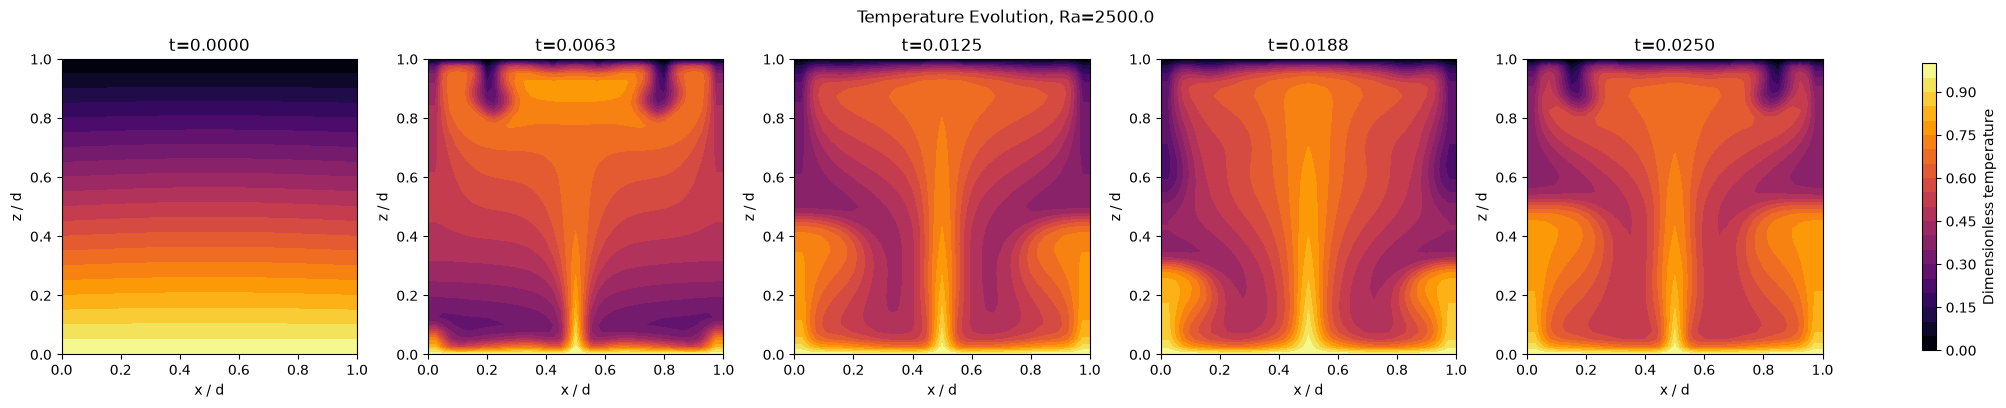


DAY 10 WORK COMPLETED
Output folder: C:\Users\athil\OneDrive\Desktop\day10_time_evolution
Files generated:
1. day10_time_history.csv
2. day10_velocity_vs_time.png
3. day10_nusselt_vs_time.png
4. day10_heat_flux_mismatch.png
5. day10_temperature_evolution.png

Note: These are exploratory results.
Check time and grid convergence before claiming steady state.


In [5]:
"""
DAY 10: TIME EVOLUTION OF MANTLE CONVECTION

Standalone program:
1. Simulates convection for Ra = 2500.
2. Records maximum velocity with time.
3. Calculates top and bottom Nusselt estimates.
4. Saves temperature snapshots.
5. Generates graphs and a CSV file.

Required libraries: numpy, scipy, matplotlib
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized


# ============================================================
# 1. SETTINGS
# ============================================================

RA = 2500.0
N = 41
END_TIME = 0.025
PERTURBATION = 0.015

DT_SAFETY = 0.20
MAX_STEPS = 200000

OUTPUT_DIR = Path("day10_time_evolution")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Day 10: Mantle Convection Time Evolution")
print("Rayleigh number =", RA)


# ============================================================
# 2. CREATE THE GRID
# ============================================================

def make_grid(n):

    x = np.linspace(0, 1, n)
    z = np.linspace(0, 1, n)

    X, Z = np.meshgrid(x, z)

    dx = x[1] - x[0]
    dz = z[1] - z[0]

    return x, z, X, Z, dx, dz


# ============================================================
# 3. NUMERICAL DERIVATIVES
# ============================================================

def laplacian(T, dx, dz):

    result = np.zeros_like(T)

    result[1:-1, 1:-1] = (
        (T[1:-1, 2:] - 2*T[1:-1, 1:-1]
         + T[1:-1, :-2]) / dx**2
        +
        (T[2:, 1:-1] - 2*T[1:-1, 1:-1]
         + T[:-2, 1:-1]) / dz**2
    )

    return result


def derivative_x(field, dx):
    return np.gradient(field, dx, axis=1, edge_order=2)


def derivative_z(field, dz):
    return np.gradient(field, dz, axis=0, edge_order=2)


# ============================================================
# 4. STREAMFUNCTION SOLVER
# ============================================================

def create_streamfunction_solver(n, dx, dz):

    m = n - 2
    size = m * m

    L = lil_matrix((size, size), dtype=float)

    def index(i, j):
        return (i - 1)*m + (j - 1)

    for i in range(1, n-1):
        for j in range(1, n-1):

            k = index(i, j)

            L[k, k] = -2/dx**2 - 2/dz**2

            if j > 1:
                L[k, index(i, j-1)] = 1/dx**2

            if j < n-2:
                L[k, index(i, j+1)] = 1/dx**2

            if i > 1:
                L[k, index(i-1, j)] = 1/dz**2

            if i < n-2:
                L[k, index(i+1, j)] = 1/dz**2

    # Factorize once to speed up repeated solves.
    solve = factorized(L.tocsc())

    def calculate_psi(rhs):

        psi = np.zeros_like(rhs)

        b = rhs[1:-1, 1:-1].ravel()

        psi[1:-1, 1:-1] = solve(b).reshape(m, m)

        return psi

    return calculate_psi


# ============================================================
# 5. TEMPERATURE BOUNDARY CONDITIONS
# ============================================================

def apply_boundaries(T):

    # Bottom hot; top cold.
    T[0, :] = 1.0
    T[-1, :] = 0.0

    # Approximate insulating sidewalls.
    T[:, 0] = T[:, 1]
    T[:, -1] = T[:, -2]

    # Reapply fixed top and bottom.
    T[0, :] = 1.0
    T[-1, :] = 0.0

    return T


# ============================================================
# 6. NUSSELT NUMBER
# ============================================================

def calculate_nusselt(T, dz):

    bottom_gradient = (
        T[1, 1:-1] - T[0, 1:-1]
    ) / dz

    top_gradient = (
        T[-1, 1:-1] - T[-2, 1:-1]
    ) / dz

    nu_bottom = -np.mean(bottom_gradient)
    nu_top = -np.mean(top_gradient)

    mismatch = (
        100 * abs(nu_bottom - nu_top)
        / max(abs(nu_bottom), abs(nu_top), 1e-12)
    )

    return nu_bottom, nu_top, mismatch


# ============================================================
# 7. INITIAL TEMPERATURE
# ============================================================

x, z, X, Z, dx, dz = make_grid(N)

T = (
    1 - Z
    + PERTURBATION
    * np.sin(np.pi*X)
    * np.sin(np.pi*Z)
)

T = apply_boundaries(T)

solve_psi = create_streamfunction_solver(N, dx, dz)


# ============================================================
# 8. SIMULATION LOOP
# ============================================================

history = []
snapshots = {}

snapshot_targets = [
    0.0,
    0.25*END_TIME,
    0.50*END_TIME,
    0.75*END_TIME,
    END_TIME
]

snapshots[snapshot_targets[0]] = T.copy()

next_snapshot = 1
time = 0.0
step = 0

print("\nStarting simulation...")

while time < END_TIME and step < MAX_STEPS:

    # Calculate flow from the temperature field.
    dTdx = derivative_x(T, dx)

    psi = solve_psi(-RA*dTdx)

    u = derivative_z(psi, dz)
    w = -derivative_x(psi, dx)

    speed = np.sqrt(u**2 + w**2)

    max_speed = np.max(speed[1:-1, 1:-1])

    # Diffusion and advection timestep restrictions.
    dt_diffusion = DT_SAFETY / (
        2*(1/dx**2 + 1/dz**2)
    )

    if max_speed > 1e-12:
        dt_advection = 0.35 / (
            max_speed*(1/dx + 1/dz)
        )
    else:
        dt_advection = dt_diffusion

    dt = min(
        dt_diffusion,
        dt_advection,
        END_TIME-time
    )

    if not np.isfinite(dt) or dt <= 0:
        raise RuntimeError("Invalid timestep.")

    # Upwind derivatives.
    dTdx_up = np.zeros_like(T)
    dTdz_up = np.zeros_like(T)

    dTdx_up[:, 1:-1] = np.where(
        u[:, 1:-1] >= 0,
        (T[:, 1:-1] - T[:, :-2])/dx,
        (T[:, 2:] - T[:, 1:-1])/dx
    )

    dTdz_up[1:-1, :] = np.where(
        w[1:-1, :] >= 0,
        (T[1:-1, :] - T[:-2, :])/dz,
        (T[2:, :] - T[1:-1, :])/dz
    )

    # Diffusion term.
    lap_T = laplacian(T, dx, dz)

    # Update the temperature.
    T_new = T.copy()

    T_new[1:-1, 1:-1] = (
        T[1:-1, 1:-1]
        + dt*(
            -u[1:-1, 1:-1]
            * dTdx_up[1:-1, 1:-1]
            -w[1:-1, 1:-1]
            * dTdz_up[1:-1, 1:-1]
            +lap_T[1:-1, 1:-1]
        )
    )

    T = apply_boundaries(T_new)

    time += dt
    step += 1

    # Calculate updated velocity and heat flux.
    psi = solve_psi(
        -RA*derivative_x(T, dx)
    )

    u = derivative_z(psi, dz)
    w = -derivative_x(psi, dx)

    speed = np.sqrt(u**2 + w**2)

    max_speed = float(
        np.max(speed[1:-1, 1:-1])
    )

    nu_bottom, nu_top, mismatch = calculate_nusselt(T, dz)

    history.append({
        "time": time,
        "max_speed": max_speed,
        "Nu_bottom": nu_bottom,
        "Nu_top": nu_top,
        "Nu_mismatch_percent": mismatch,
        "temperature_min": np.min(T),
        "temperature_max": np.max(T)
    })

    # Save snapshots when target times are reached.
    while (
        next_snapshot < len(snapshot_targets)
        and time >= snapshot_targets[next_snapshot]
    ):
        target = snapshot_targets[next_snapshot]
        snapshots[target] = T.copy()
        next_snapshot += 1

    if step % 100 == 0:
        print(
            f"Step {step}, time={time:.6f}, "
            f"max speed={max_speed:.5g}, "
            f"Nu_bottom={nu_bottom:.5f}"
        )

if time < END_TIME:
    print("WARNING: Maximum step count reached.")

snapshots[END_TIME] = T.copy()

print("\nSimulation finished.")
print("Steps:", step)
print("Final time:", time)


# ============================================================
# 9. SAVE TIME HISTORY AS CSV
# ============================================================

csv_file = OUTPUT_DIR / "day10_time_history.csv"

with open(csv_file, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f, fieldnames=list(history[0].keys())
    )

    writer.writeheader()
    writer.writerows(history)

print("Saved:", csv_file)


# ============================================================
# 10. MAXIMUM VELOCITY VS TIME
# ============================================================

times = [row["time"] for row in history]
speeds = [row["max_speed"] for row in history]

plt.figure(figsize=(7, 5))
plt.plot(times, speeds)

plt.xlabel("Dimensionless time")
plt.ylabel("Maximum dimensionless velocity")
plt.title(f"Maximum Velocity vs Time, Ra={RA}")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day10_velocity_vs_time.png",
    dpi=180
)

plt.show()


# ============================================================
# 11. NUSSELT NUMBER VS TIME
# ============================================================

nu_bottom = [row["Nu_bottom"] for row in history]
nu_top = [row["Nu_top"] for row in history]

plt.figure(figsize=(7, 5))

plt.plot(times, nu_bottom, label="Bottom Nu")
plt.plot(times, nu_top, label="Top Nu")

plt.axhline(
    1, color="black", linestyle=":",
    label="Conduction reference Nu=1"
)

plt.xlabel("Dimensionless time")
plt.ylabel("Nusselt-number estimate")
plt.title(f"Nusselt Number vs Time, Ra={RA}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day10_nusselt_vs_time.png",
    dpi=180
)

plt.show()


# ============================================================
# 12. TOP-BOTTOM HEAT-FLUX MISMATCH VS TIME
# ============================================================

mismatch = [
    row["Nu_mismatch_percent"]
    for row in history
]

plt.figure(figsize=(7, 5))
plt.plot(times, mismatch)

plt.xlabel("Dimensionless time")
plt.ylabel("Top-bottom Nu difference (%)")
plt.title("Heat-Flux Consistency vs Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day10_heat_flux_mismatch.png",
    dpi=180
)

plt.show()


# ============================================================
# 13. TEMPERATURE SNAPSHOTS
# ============================================================

items = sorted(snapshots.items(), key=lambda item: item[0])

fig, axes = plt.subplots(
    1, len(items),
    figsize=(4*len(items), 4),
    squeeze=False,
    constrained_layout=True
)

last_contour = None

for ax, (snapshot_time, temperature) in zip(axes[0], items):

    last_contour = ax.contourf(
        X, Z, temperature,
        levels=21,
        cmap="inferno"
    )

    ax.set_title(f"t={snapshot_time:.4f}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.colorbar(
    last_contour,
    ax=axes.ravel().tolist(),
    label="Dimensionless temperature",
    shrink=0.85
)

fig.suptitle(f"Temperature Evolution, Ra={RA}")

fig.savefig(
    OUTPUT_DIR / "day10_temperature_evolution.png",
    dpi=180
)

plt.show()


# ============================================================
# 14. FINISH
# ============================================================

print("\n" + "="*50)
print("DAY 10 WORK COMPLETED")
print("="*50)

print("Output folder:", OUTPUT_DIR.resolve())
print("Files generated:")
print("1. day10_time_history.csv")
print("2. day10_velocity_vs_time.png")
print("3. day10_nusselt_vs_time.png")
print("4. day10_heat_flux_mismatch.png")
print("5. day10_temperature_evolution.png")

print("\nNote: These are exploratory results.")
print("Check time and grid convergence before claiming steady state.")